In [27]:
# Load all libraries
# import library pandas 
import pandas as pd
# import visualisation library matplotlib
import matplotlib.pyplot as plt
# import library (LabelEncoder from sklearn) for encoding categorical columns 
from sklearn.preprocessing import LabelEncoder
# import from sklearn possibility to split dataset to test and train
from sklearn.model_selection import train_test_split
# import from sklearn metrics to evaluate the model 
from sklearn.metrics import root_mean_squared_error
# import from sklearn linear model that we want to use 
from sklearn.linear_model import Ridge
# import from sklearn linear model that we want to use 
from sklearn.linear_model import LinearRegression


In [2]:
# Load dataset 
df = pd.read_csv('regression.csv', sep=',')

In [3]:
# Look into the first 10 rows of a dataframe
df.head()

,Geschäftspartner ID,Buchwert,Zinsen,Boni-Rating,CO2 (scope 1+2),Energie,Müll,Abwasser,Produktart,Bundesland,NACE (Zuordnung der Beschreibung),SUM ESG
0,1,80.0,0.05,10,100,50,200,300,Immobilienfinanzierung,Schleswig-Holstein,10_6,650
1,1,80.0,0.05,10,100,50,200,300,Immobilienfinanzierung,Schleswig-Holstein,10_6,650
2,1,80.0,0.05,10,100,50,200,300,Immobilienfinanzierung,Schleswig-Holstein,10_7,650
3,2,10.0,0.02,9,167,1483,782,890,Konsumentenkredit,Baden-Wurttemberg,25_1,3322
4,2,10.0,0.02,9,167,1483,782,890,Konsumentenkredit,Baden-Wurttemberg,25_1,3322


In [4]:
# TODO Exercise : Look into the shape of dataframe
df.shape

(256, 12)

In [5]:
# TODO Exercise : Look into the informations about your dataframe 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 256 entries, 0 to 255
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Geschäftspartner ID                256 non-null    int64  
 1   Buchwert                           256 non-null    float64
 2   Zinsen                             256 non-null    float64
 3   Boni-Rating                        256 non-null    int64  
 4   CO2 (scope 1+2)                    256 non-null    int64  
 5   Energie                            256 non-null    int64  
 6   Müll                               256 non-null    int64  
 7   Abwasser                           256 non-null    int64  
 8   Produktart                         256 non-null    str    
 9   Bundesland                         256 non-null    str    
 10  NACE (Zuordnung der Beschreibung)  256 non-null    str    
 11  SUM ESG                            256 non-null    int64  
dtypes: fl

In [6]:
# Set up data frame id for a variable Geschäftspartner ID
df = df.set_index('Geschäftspartner ID')

# Exploratory Data Analysis

Categorical Columns

In [7]:
# Plot categorical columns to analyse them 

<Axes: xlabel='Bundesland'>

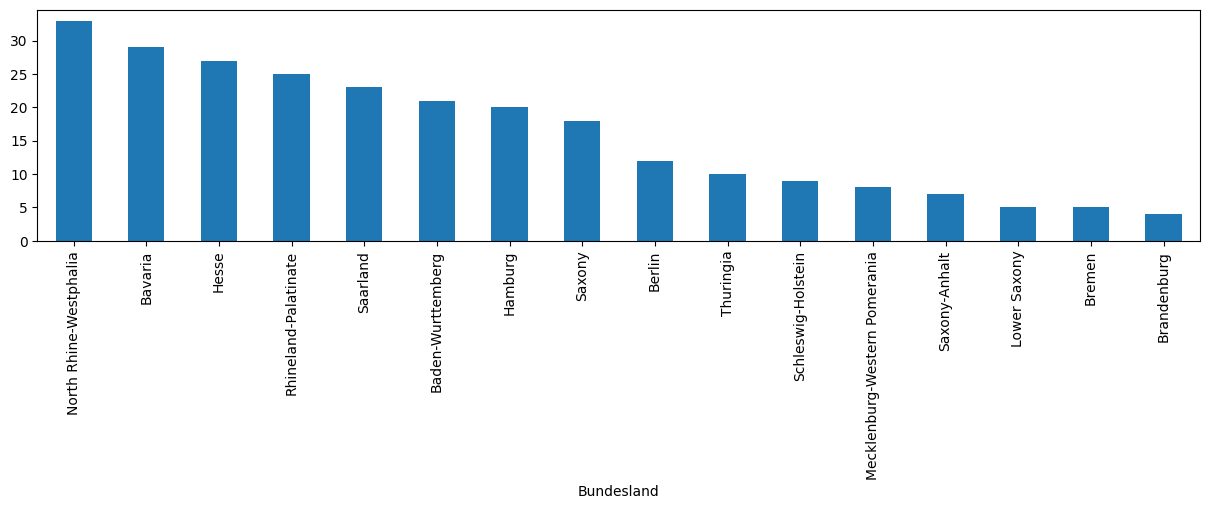

In [8]:
df['Bundesland'].value_counts().plot(kind='bar', figsize=(15,3))

<Axes: xlabel='Produktart'>

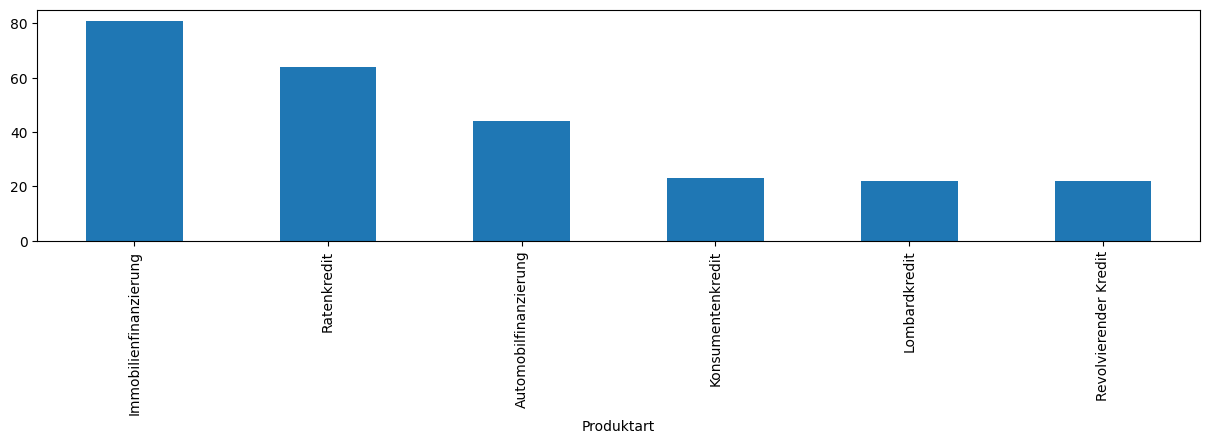

In [9]:
# TODO Exercise : Create a bar plot for variable 'Produktart'
df['Produktart'].value_counts().plot(kind='bar',  figsize=(15,3))

<Axes: xlabel='NACE (Zuordnung der Beschreibung)'>

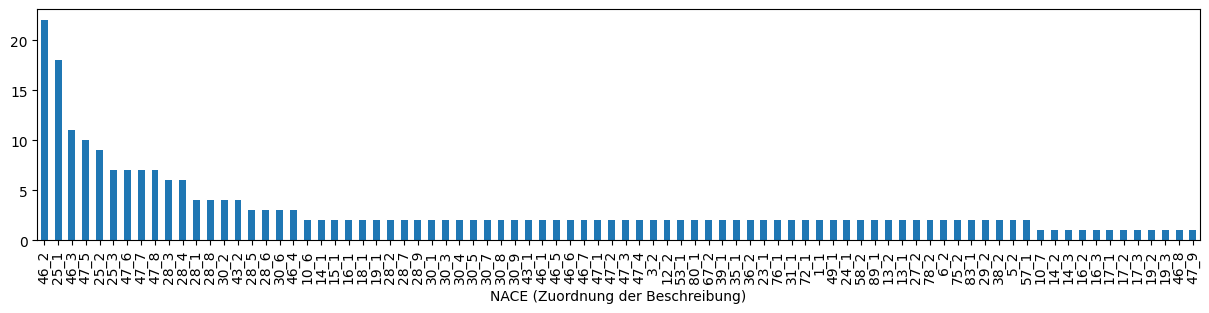

In [10]:
# TODO Exercise : Create a bar plot for variable 'NACE (Zuordnung der Beschreibung)'
df['NACE (Zuordnung der Beschreibung)'].value_counts().plot(kind='bar',  figsize=(15,3))

<Axes: xlabel='Boni-Rating'>

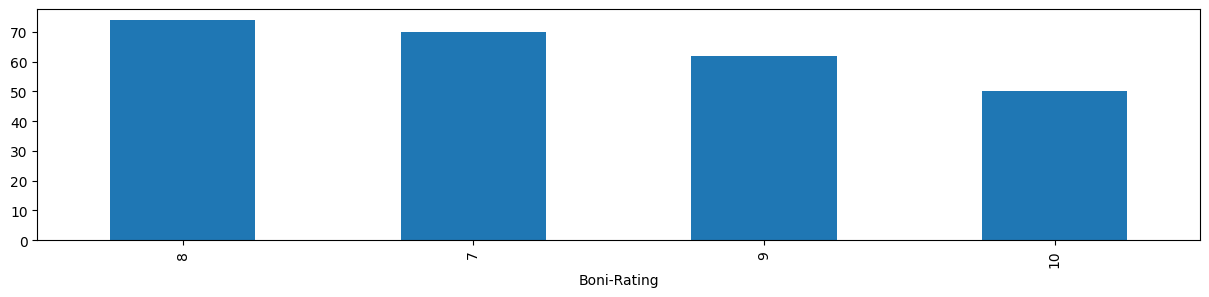

In [11]:
# TODO Exercise : Create a bar plot for variable 'Boni-Rating' 
df['Boni-Rating'].value_counts().plot(kind='bar',  figsize=(15,3))

# Dataset Preparation



In [12]:
# Further analysis of the dataset. Some of the variables are in the form of text. 
# This means they are not usable in our model. To use them we need to change their format.

In [13]:
# Encode variable 'Bundesland'
df['Bundesland']=df['Bundesland'].astype('category').cat.codes

In [14]:
# TODO Exercise : Encode variable 'NACE (Zuordnung der Beschreibung)'
df['NACE (Zuordnung der Beschreibung)']=df['NACE (Zuordnung der Beschreibung)'].astype('category').cat.codes

In [15]:
# Some of the variables are not necessary for the model. 
# They don't have a positive impact on it. We want to remove those columns.

In [16]:
# Remove unnecessary columns 
df = df.drop(['Zinsen', 'Boni-Rating'] , axis= 1)

In [17]:
# TODO Exercise : Remove column 'Produktart'
df = df.drop(['Produktart'] , axis= 1)

In [18]:
# In a dataset there might also be some duplicates. 
# This would make our results invalid. That's why we want to get rid of duplicates. 

In [19]:
df = df.drop_duplicates()

# To move forward to training we need to split our dataset to dependent and independent variables.
# So y and X dataset. 

In [21]:
# Split dataset to y and X datasets 
y = df['SUM ESG']
X = df.drop(['SUM ESG'], axis=1)

# Train your dataset 

1. Split to train and test set 

In [22]:
# To proceed the training datasets needs to be split into train and testing samples. 

In [23]:
y.rename({'SUM ESG':'y'}, inplace=True)

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

2. Regression

In [25]:
# Run a normal regression 

In [29]:
y_pred_lin = LinearRegression()
fit_model = y_pred_lin.fit(X_train, y_train)
pred = fit_model.predict(X_test)
mae_lin = root_mean_squared_error(y_test, pred)
mae_lin


8.962983333288707e-13

3. Ridge Regression

In [41]:
# TODO Exercise : Run a ridge regression 

In [30]:
clf = Ridge(alpha=0.001)
y_pred_ridge = clf.fit(X_train, y_train)
pred_ridge = y_pred_ridge.predict(X_test)
mae_ridge=root_mean_squared_error(y_test, pred_ridge)
mae_ridge

1.3536099382772601e-07

5. Check Predictions

In [ ]:
# Run code to check your predictions 

In [31]:
id = X.reset_index()['Geschäftspartner ID']
some_data = X
some_labels = y
df_results = pd.DataFrame({'Id' : id.to_list(),
                            'Predictions_lin':y_pred_lin.predict(some_data), 
                           'Predictions_ridge':clf.predict(some_data), 
                           'Labels_lin': list(some_labels)})
df_results.sample(5)

,Id,Predictions_lin,Predictions_ridge,Labels_lin
83,56,2230.0,2230.0,2230
111,74,1653.0,1653.0,1653
65,45,1715.0,1715.0,1715
67,45,1715.0,1715.0,1715
91,62,3039.0,3039.0,3039
